# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared chart styling: one accent color, light grid, readable labels
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "axes.titleweight": "bold",
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

# Create connection to database
conn = sqlite3.connect("data.sqlite")

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# California customers with a high credit limit (over 25,000)
df_ca_high_credit = pd.read_sql("""
SELECT
    customerNumber,
    customerName,
    contactFirstName,
    contactLastName,
    phone,
    city,
    state,
    CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY creditLimit DESC;
""", conn)
df_ca_high_credit

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# International (non-US) customers with "Collect" in their name
df_intl_collect = pd.read_sql("""
SELECT
    customerNumber,
    customerName,
    contactFirstName,
    contactLastName,
    city,
    country
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
""", conn)
df_intl_collect

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

**Answer:**

The `WHERE` clause that I used works like a checklist that every customer has to pass before showing up in the results. It has two conditions joined by `AND`, so a customer is only included if **both** are true:

1. **`country <> 'USA'`**: the `<>` operator means "is not equal to." Any customer whose country is the USA is removed, which leaves only international customers.
2. **`customerName LIKE '%Collect%'`**: `LIKE` searches for a pattern in the name. The `%` symbols mean "any text can come before or after," so the name only has to *contain* "Collect" somewhere. This catches "Collectables," "Collectors" and "Collections" (for example, *Australian Collectors, Co.* and *Clover Collections, Co.*) while excluding names without it.

Because the two conditions are combined with `AND`, a US customer with "Collect" in its name (such as *Cambridge Collectables Co.*) is excluded, and so is an international customer without it. The result is exactly the 15 international "Collect" partners the team asked for.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQL query that returns the information required to address this ask.

In [4]:
# Average credit limit by US state (with customer counts for context)
df_state_credit = pd.read_sql("""
SELECT
    state,
    COUNT(*) AS num_customers,
    ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
""", conn)
df_state_credit

,state,num_customers,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

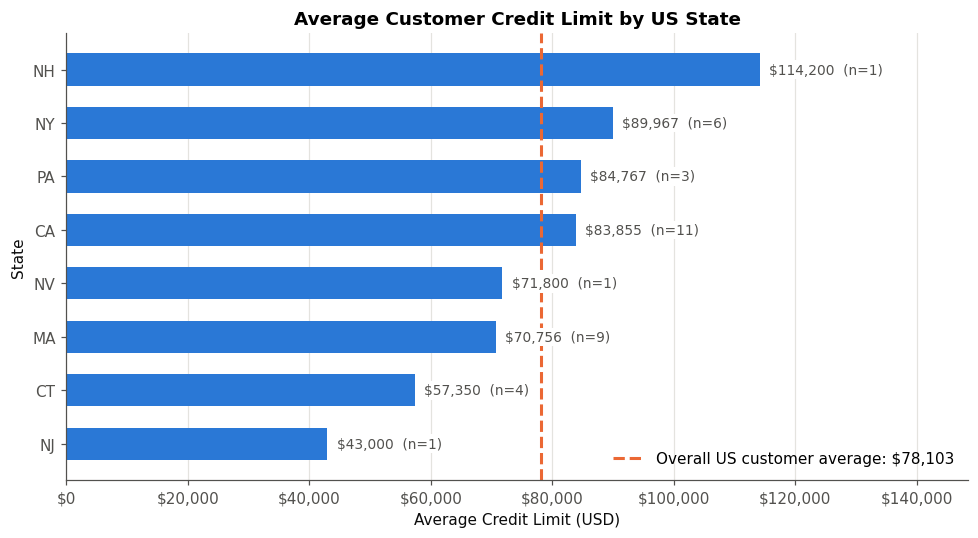

In [5]:
# Produce a visual to represent the average credit limit by state
plt.figure(figsize=(9, 5))
plot_df = df_state_credit.sort_values("avg_credit_limit")
bars = plt.barh(plot_df["state"], plot_df["avg_credit_limit"], color=BLUE, height=0.6)

# Label each bar with its average and customer count (small states need context)
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    plt.text(bar.get_width() + 1500, bar.get_y() + bar.get_height() / 2,
             f"${row.avg_credit_limit:,.0f}  (n={row.num_customers})",
             va="center", fontsize=9, color=MUTED, zorder=4,
             bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

# Reference line: overall average across all US customers (weighted by customer count)
us_avg = (plot_df["avg_credit_limit"] * plot_df["num_customers"]).sum() / plot_df["num_customers"].sum()
plt.axvline(us_avg, color=ORANGE, linestyle="--", linewidth=2,
            label=f"Overall US customer average: ${us_avg:,.0f}")

plt.title("Average Customer Credit Limit by US State")
plt.xlabel("Average Credit Limit (USD)")
plt.ylabel("State")
plt.xlim(0, plot_df["avg_credit_limit"].max() * 1.3)
plt.legend(loc="lower right", frameon=False)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
# Top 10 customers by total payments made
df_top_customers = pd.read_sql("""
SELECT
    c.customerNumber,
    c.customerName,
    ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers AS c
JOIN payments AS p
    ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
""", conn)
df_top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

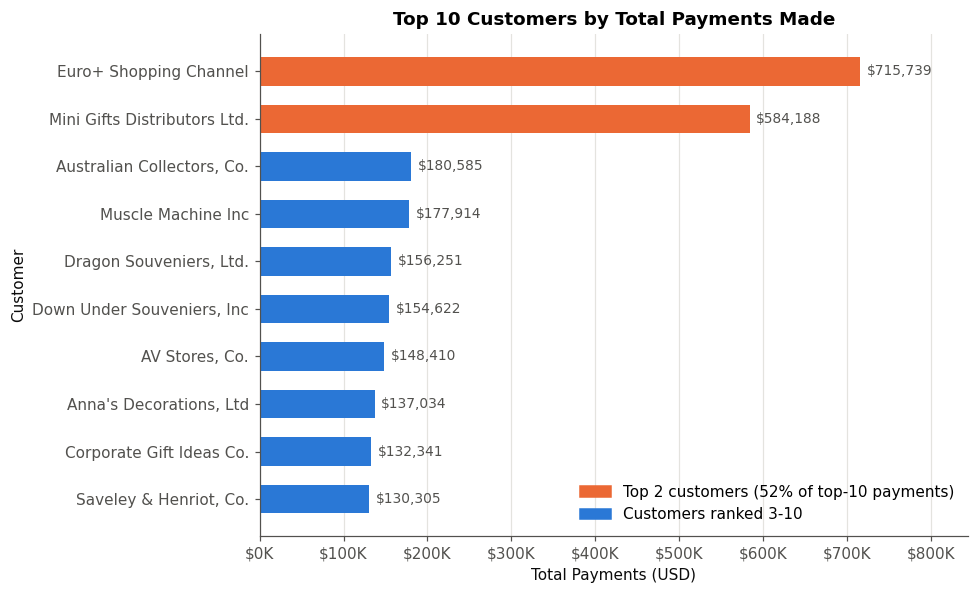

In [7]:
# Produce a visual to represent the top ten customers in terms of total payments
plt.figure(figsize=(9, 5.5))
plot_df = df_top_customers.sort_values("total_payments")
# Highlight the top 2 customers, who are far ahead of the rest of the list
top2 = plot_df["total_payments"].rank(ascending=False) <= 2
colors = [ORANGE if is_top else BLUE for is_top in top2]
bars = plt.barh(plot_df["customerName"], plot_df["total_payments"], color=colors, height=0.6)
top2_share = plot_df.loc[top2, "total_payments"].sum() / plot_df["total_payments"].sum()
plt.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color=ORANGE, label=f"Top 2 customers ({top2_share:.0%} of top-10 payments)"),
    plt.Rectangle((0, 0), 1, 1, color=BLUE, label="Customers ranked 3-10"),
], loc="lower right", frameon=False)

for bar in bars:
    plt.text(bar.get_width() + 8000, bar.get_y() + bar.get_height() / 2,
             f"${bar.get_width():,.0f}", va="center", fontsize=9, color=MUTED)

plt.title("Top 10 Customers by Total Payments Made")
plt.xlabel("Total Payments (USD)")
plt.ylabel("Customer")
plt.xlim(0, plot_df["total_payments"].max() * 1.18)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:,.0f}K"))
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
# For each customer, every product they bought 10+ units of, sorted by total purchased (ascending)
df_customer_products = pd.read_sql("""
SELECT
    c.customerNumber,
    c.customerName,
    p.productCode,
    p.productName,
    SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_purchased
FROM customers AS c
JOIN orders AS o
    ON c.customerNumber = o.customerNumber
JOIN orderdetails AS od
    ON o.orderNumber = od.orderNumber
JOIN products AS p
    ON od.productCode = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
ORDER BY total_quantity_purchased ASC;
""", conn)
df_customer_products

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# Number of distinct products and total quantity ordered for each product line
df_product_lines = pd.read_sql("""
SELECT
    p.productLine,
    COUNT(DISTINCT p.productCode) AS num_products,
    SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_ordered
FROM products AS p
JOIN orderdetails AS od
    ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
""", conn)
df_product_lines

,productLine,num_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

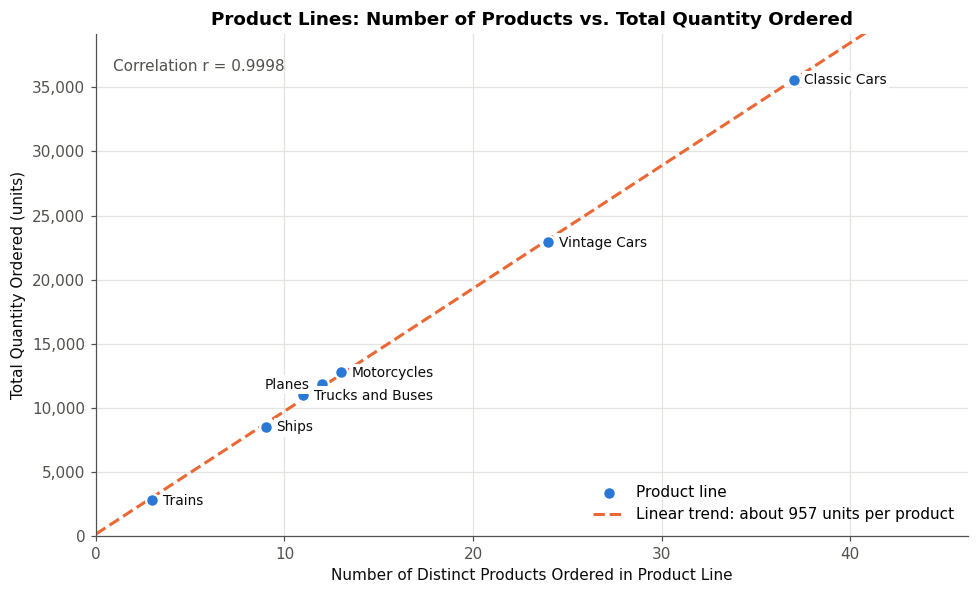

In [10]:
# Produce a visual to represent the relation between number of products and the total amount ordered
plt.figure(figsize=(9, 5.5))
x, y = df_product_lines["num_products"], df_product_lines["total_quantity_ordered"]
plt.scatter(x, y, s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3, label="Product line")

# Least-squares trend line: slope = extra units ordered per additional product
slope, intercept = np.polyfit(x, y, 1)
trend_x = np.array([0, x.max() * 1.15])
plt.plot(trend_x, slope * trend_x + intercept, color=ORANGE, linestyle="--", linewidth=2,
         label=f"Linear trend: about {slope:,.0f} units per product", zorder=2)
plt.legend(loc="lower right", frameon=False)

# Label each product line (7 points, so every label stays readable)
for _, row in df_product_lines.iterrows():
    # Planes sits between Motorcycles and Trucks and Buses, so its label goes on the left
    offset, ha = ((-8, -3), "right") if row.productLine == "Planes" else ((7, -3), "left")
    plt.annotate(row.productLine, (row.num_products, row.total_quantity_ordered), ha=ha,
                 xytext=offset, textcoords="offset points", fontsize=9, color=INK, zorder=4,
                 bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

r = x.corr(y)
plt.title("Product Lines: Number of Products vs. Total Quantity Ordered")
plt.xlabel("Number of Distinct Products Ordered in Product Line")
plt.ylabel("Total Quantity Ordered (units)")
plt.text(0.02, 0.95, f"Correlation r = {r:.4f}", transform=plt.gca().transAxes,
         fontsize=10, color=MUTED, va="top")
plt.xlim(0, x.max() * 1.25)
plt.ylim(0, y.max() * 1.1)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

**Answer:**

I used a **scatter plot** because the question asks about the *relationship* between two numbers for each product line: how many products the line offers, and how many units customers ordered. A scatter plot puts one number on each axis, so every product line becomes one dot. If the dots climb from the bottom-left to the top-right, lines with more products also sell more units. A bar chart could show each number separately, but it would make you compare two charts side by side to see that relationship. I labeled every dot by name because there are only 7 lines, and I added the correlation (r) as a single summary number.

**What it shows:** the dots form an almost perfectly straight upward line (r ≈ 1.0). **Classic Cars** (37 products, about 35,600 units) and **Vintage Cars** (24 products, about 22,900 units) lead, while **Trains** (3 products, about 2,800 units) trails. So in this data, product lines with more products *do* get more orders. Each product sells roughly 900–1,000 units no matter which line it belongs to, so no single line stands out as much more or less popular per product. For the product team, that suggests expanding the variety in a line is the main lever for increasing its volume. Lines like Trains and Ships are candidates to either grow or review. Correlation alone doesn't prove that adding products *causes* more orders, so that should be tested before major investment.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
# Employees in offices with fewer than 5 employees, with job and supervisor details
df_remote_employees = pd.read_sql("""
SELECT
    e.employeeNumber,
    e.firstName,
    e.lastName,
    e.jobTitle,
    e.email,
    e.officeCode,
    o.city AS officeCity,
    o.country AS officeCountry,
    e.reportsTo AS supervisorNumber,
    s.firstName || ' ' || s.lastName AS supervisorName,
    s.jobTitle AS supervisorJobTitle
FROM employees AS e
JOIN offices AS o
    ON e.officeCode = o.officeCode
LEFT JOIN employees AS s
    ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.lastName;
""", conn)
df_remote_employees

,employeeNumber,firstName,lastName,jobTitle,email,officeCode,officeCity,officeCountry,supervisorNumber,supervisorName,supervisorJobTitle
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,ykato@classicmodelcars.com,5,Tokyo,Japan,1621,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,mnishi@classicmodelcars.com,5,Tokyo,Japan,1056,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,6,Sydney,Australia,1056,Mary Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

**Answer:**

I broke the request into two separate questions: **(1) which offices have fewer than 5 employees?** and **(2) who works in those offices, and who are their supervisors?** The first is an aggregate question, and the second asks for individual employee rows, so they can't be answered in a single `GROUP BY`. Grouping would collapse the employees into one row per office.

The subquery answers question 1 on its own:

```sql
SELECT officeCode FROM employees GROUP BY officeCode HAVING COUNT(*) < 5
```

It groups employees by office and keeps only offices whose headcount is under 5. I used `HAVING` rather than `WHERE` because the condition is on an aggregate (`COUNT(*)`), which only exists after grouping. I ran it by itself first to check it: it returns offices 2, 3, 5, 6 and 7. Offices 1 (6 employees) and 4 (5 employees) are correctly left out, since 5 is not *fewer than* 5.

The main query then answers question 2 using `WHERE e.officeCode IN (subquery)`, which keeps only employees whose office is in that list. To meet the request for job and supervisor details, I joined `offices` for the office location and **self-joined** `employees` (alias `s`) on `e.reportsTo = s.employeeNumber` to get each supervisor's name and title. I made that a `LEFT JOIN` so an employee with no supervisor would still appear instead of being silently dropped. The result is 12 employees across the 5 small offices, each with their own role and their supervisor's.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

### Initial Exploration: Scope of the Data

I start broad: how big is each table, and how complete is the core movie data?

In [14]:
# Row counts for every table
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table';", conn4)["name"]
pd.DataFrame({
    "table": tables,
    "rows": [pd.read_sql(f"SELECT COUNT(*) AS n FROM {t};", conn4).iloc[0, 0] for t in tables],
})

,table,rows
0,movie_basics,146144
1,directors,291174
2,known_for,1638260
3,movie_akas,331703
4,movie_ratings,73856
5,persons,606648
6,principals,1028186
7,writers,255873


In [15]:
# Movies per start_year: confirms the 2010-2019 range and shows rows that must be excluded
movies_by_year = pd.read_sql("""
SELECT start_year, COUNT(*) AS num_movies
FROM movie_basics
GROUP BY start_year
ORDER BY start_year;
""", conn4)
movies_by_year.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
start_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2115
num_movies,11849,12900,13787,14709,15589,16243,17272,17504,16849,8379,937,83,32,5,2,1,1,1,1


In [16]:
# Completeness of the key fields for movies released 2010-2019
pd.read_sql("""
SELECT
    COUNT(*) AS movies_2010_2019,
    SUM(b.runtime_minutes IS NULL) AS missing_runtime,
    SUM(b.genres IS NULL) AS missing_genres,
    SUM(r.movie_id IS NULL) AS missing_rating,
    ROUND(100.0 * SUM(r.movie_id IS NOT NULL) / COUNT(*), 1) AS pct_with_rating
FROM movie_basics AS b
LEFT JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year <= 2019;
""", conn4)

,movies_2010_2019,missing_runtime,missing_genres,missing_rating,pct_with_rating
0,145081,30765,5359,71225,50.9


In [17]:
# How many votes do ratings rest on? Many ratings come from very few voters.
pd.read_sql("""
SELECT
    COUNT(*) AS rated_movies,
    SUM(numvotes < 100) AS under_100_votes,
    SUM(numvotes >= 1000) AS at_least_1000_votes,
    ROUND(AVG(averagerating), 2) AS avg_rating,
    MAX(numvotes) AS max_votes
FROM movie_ratings;
""", conn4)

,rated_movies,under_100_votes,at_least_1000_votes,avg_rating,max_votes
0,73856,45103,9617,6.33,1841066


### Focus Area: Genre, Audience Ratings and Audience Reach

Genre is the most direct lever a studio controls, so I focus on how genres compare on **quality** (`averagerating`) and **reach** (`numvotes`, a proxy for audience size).

Data rules applied, as the instructions require:
- Only movies with `start_year <= 2019`
- Null `genres` and movies without ratings are excluded (inner join, `IS NOT NULL`); nothing is filled in
- `genres` holds up to 3 comma-separated values, so each movie is counted once per genre (split in pandas)

In [18]:
# Base dataset: rated 2010-2019 movies with a genre
movies = pd.read_sql("""
SELECT
    b.movie_id,
    b.primary_title,
    b.start_year,
    b.runtime_minutes,
    b.genres,
    r.averagerating,
    r.numvotes
FROM movie_basics AS b
JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year <= 2019
  AND b.genres IS NOT NULL;
""", conn4)

# One row per movie-genre pair
movie_genres = movies.assign(genre=movies["genres"].str.split(",")).explode("genre")

genre_all = (movie_genres.groupby("genre")
             .agg(movies=("movie_id", "count"),
                  avg_rating=("averagerating", "mean"),
                  median_votes=("numvotes", "median"))
             .sort_values("movies", ascending=False)
             .round(2))
print(f"{len(movies):,} rated movies with a genre (2010-2019)")
genre_all.head(12)

73,052 rated movies with a genre (2010-2019)


,movies,avg_rating,median_votes
genre,,,
Drama,30788,6.40,71.0
Documentary,17753,7.33,19.0
Comedy,17290,6.00,95.0
Thriller,8217,5.64,132.0
Horror,7674,5.00,79.0
Action,6988,5.81,170.0
Romance,6589,6.15,116.0
Crime,4611,6.12,169.0
Adventure,3817,6.20,111.0


**First pattern:** with every rated movie included, the highest-rated genres (Documentary 7.33, Biography 7.16, History 7.04) have the *smallest* audiences (median of only 19–40 votes). Small groups of voters can push averages up, so these raw numbers mix real quality with tiny, enthusiastic audiences.

To compare genres fairly, I keep only movies with **at least 1,000 votes** (an established audience) and genres with **at least 100** such movies.

In [19]:
established = movie_genres[movie_genres["numvotes"] >= 1000]

genre_summary = (established.groupby("genre")
                 .agg(movies=("movie_id", "count"),
                      avg_rating=("averagerating", "mean"),
                      median_votes=("numvotes", "median"))
                 .query("movies >= 100"))

rating_cut = genre_summary["avg_rating"].median()
votes_cut = genre_summary["median_votes"].median()
genre_summary["high_rating_and_reach"] = ((genre_summary["avg_rating"] > rating_cut)
                                          & (genre_summary["median_votes"] > votes_cut))

print(f"{established['movie_id'].nunique():,} movies with 1,000+ votes")
print(f"Median genre rating: {rating_cut:.2f} | median genre audience: {votes_cut:,.0f} votes")
genre_summary.sort_values("avg_rating", ascending=False).round(2)

9,615 movies with 1,000+ votes
Median genre rating: 6.33 | median genre audience: 3,792 votes


,movies,avg_rating,median_votes,high_rating_and_reach
genre,,,,
Documentary,741,7.27,2259.0,False
Biography,701,6.96,4559.0,True
Sport,196,6.93,2753.5,False
History,387,6.89,3590.0,False
Music,283,6.75,3637.0,False
War,163,6.72,3907.0,True
Animation,376,6.68,5289.5,True
Drama,5047,6.49,3789.0,False
Romance,1351,6.34,3563.0,False


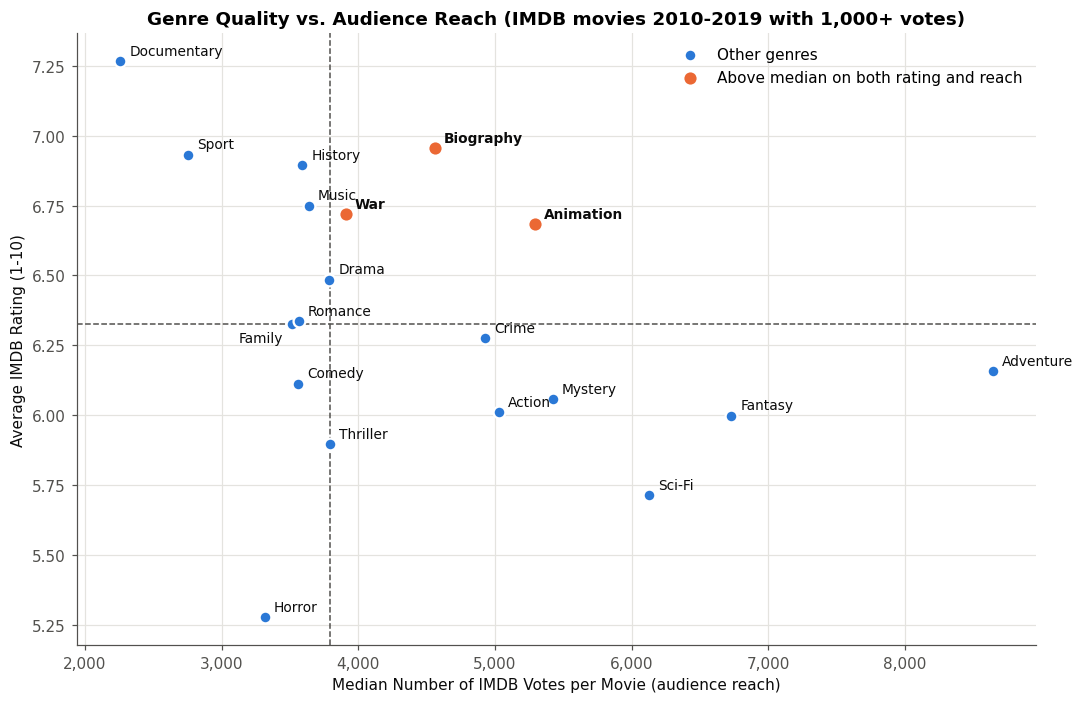

In [20]:
# Visual supporting the business question: quality vs. reach by genre
plt.figure(figsize=(10, 6.5))
standout = genre_summary[genre_summary["high_rating_and_reach"]]
others = genre_summary[~genre_summary["high_rating_and_reach"]]

plt.scatter(others["median_votes"], others["avg_rating"], s=60, color=BLUE,
            edgecolor="white", linewidth=1.5, zorder=3, label="Other genres")
plt.scatter(standout["median_votes"], standout["avg_rating"], s=90, color=ORANGE,
            edgecolor="white", linewidth=1.5, zorder=4,
            label="Above median on both rating and reach")

plt.axvline(votes_cut, color=MUTED, linestyle="--", linewidth=1)
plt.axhline(rating_cut, color=MUTED, linestyle="--", linewidth=1)

for genre, row in genre_summary.iterrows():
    # Family and Romance sit almost on top of each other, so Family's label goes below-left
    offset, ha = ((-6, -12), "right") if genre == "Family" else ((6, 4), "left")
    plt.annotate(genre, (row.median_votes, row.avg_rating), xytext=offset, ha=ha,
                 textcoords="offset points", fontsize=9,
                 color=INK, fontweight="bold" if row.high_rating_and_reach else "normal")

plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.title("Genre Quality vs. Audience Reach (IMDB movies 2010-2019 with 1,000+ votes)")
plt.xlabel("Median Number of IMDB Votes per Movie (audience reach)")
plt.ylabel("Average IMDB Rating (1-10)")
plt.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig("images/genre_quality_vs_reach.png", dpi=200, bbox_inches="tight")
plt.show()

**Second pattern: quality and reach trade off.** Genres with the biggest audiences (Adventure, Fantasy, Sci-Fi, Mystery, Action) sit *below* the median rating, while the highest-rated genres (Documentary, Sport, History) sit *below* the median reach. Only **Biography, Animation and War** clear both medians. Horror is the weakest genre on both measures.

In [21]:
# Is the standout genres' performance consistent over time, or driven by one year?
consistency = (established[established["genre"].isin(standout.index)]
               .groupby(["start_year", "genre"])["averagerating"].mean()
               .unstack().round(2))
consistency

genre,Animation,Biography,War
start_year,,,
2010,6.74,6.94,6.90
2011,6.50,6.75,6.54
2012,6.72,7.09,6.45
2013,6.72,6.92,6.65
2014,6.70,7.05,6.95
2015,6.87,7.08,6.63
2016,6.88,6.97,6.65
2017,6.33,6.83,6.74
2018,6.82,7.01,6.83


In [22]:
# Runtime vs. rating and reach (movies with 1,000+ votes and a plausible runtime)
runtime = movies[(movies["numvotes"] >= 1000) & movies["runtime_minutes"].between(40, 240)].copy()
runtime["runtime_band"] = pd.cut(runtime["runtime_minutes"], [40, 90, 100, 110, 120, 150, 240],
                                 labels=["40-90", "90-100", "100-110", "110-120", "120-150", "150-240"])
runtime.groupby("runtime_band", observed=True).agg(
    movies=("movie_id", "count"),
    avg_rating=("averagerating", "mean"),
    median_votes=("numvotes", "median"),
).round(2)

,movies,avg_rating,median_votes
runtime_band,,,
40-90,2248,5.73,2359.0
90-100,2551,6.03,3336.0
100-110,1815,6.39,4298.0
110-120,1142,6.60,5034.5
120-150,1471,6.79,4417.0
150-240,373,6.97,4583.0


### Summary of Initial Exploration Findings

- **Scope:** 146,144 movies, but 1,063 have a `start_year` after 2019 (one as late as 2115) and were excluded. Releases grow steadily from 2010 to 2017; 2019 is only partly covered.
- **Ratings coverage is limited:** only about half of 2010–2019 movies have a rating, and 61% of rated movies have fewer than 100 votes, so ratings on small films are noisy.
- **Raw ratings favor niche genres:** Documentary, Biography and History rate highest overall, but on very small audiences.
- **Among established movies (1,000+ votes), quality and reach trade off:** blockbuster genres (Adventure, Sci-Fi, Fantasy, Action) draw the largest audiences but rate below the median; Documentary rates highest but reaches the fewest viewers.
- **Biography, Animation and War** are the only genres above the median on *both* rating and reach. Horror is weakest on both.
- **Consistency over time:** Biography stays between 6.54 and 7.09 in every year from 2010 to 2019. Animation is less steady (6.27–6.88, with dips in 2017 and 2019), and War has the smallest sample (163 movies).
- **Runtime:** among established movies, longer films rate higher and draw more votes. Movies of 120+ minutes outperform those under 90 minutes on both measures.

### Business Question for Further Analysis

> **Which film genres consistently combine above-average audience ratings with above-average audience reach, and should a studio launching its first original films prioritize Biography and Animation over high-volume genres like Action and Adventure?**

This question comes directly from the quality-vs-reach trade-off above. It is specific (genre-level ratings and votes), relevant (genre choice drives a new studio's risk), and answerable with this data. Deeper analysis would add year-over-year consistency, genre combinations (e.g. Animation + Adventure), and the directors and writers behind the top performers.

### Data Cleaning Tasks Identified

The queries below provide evidence for each task. As instructed, these tasks are identified, not performed.

In [23]:
cleaning_checks = pd.read_sql("""
SELECT 'movie_basics: start_year after 2019 (incl. 2115 typo)' AS issue, COUNT(*) AS rows_affected
FROM movie_basics WHERE start_year > 2019
UNION ALL
SELECT 'movie_basics: null runtime_minutes', COUNT(*) FROM movie_basics WHERE runtime_minutes IS NULL
UNION ALL
SELECT 'movie_basics: runtime over 300 min (max 51,420)', COUNT(*) FROM movie_basics WHERE runtime_minutes > 300
UNION ALL
SELECT 'movie_basics: runtime under 40 min (shorts?)', COUNT(*) FROM movie_basics WHERE runtime_minutes < 40
UNION ALL
SELECT 'movie_basics: null genres', COUNT(*) FROM movie_basics WHERE genres IS NULL
UNION ALL
SELECT 'movie_basics: multi-value genres (comma-separated)', COUNT(*) FROM movie_basics WHERE genres LIKE '%,%'
UNION ALL
SELECT 'movie_basics: duplicate title + year pairs', COUNT(*) FROM (
    SELECT primary_title, start_year FROM movie_basics GROUP BY 1, 2 HAVING COUNT(*) > 1)
UNION ALL
SELECT 'movie_basics: primary_title differs from original_title', COUNT(*)
FROM movie_basics WHERE primary_title <> original_title
UNION ALL
SELECT 'movie_ratings: under 100 votes (unreliable average)', COUNT(*) FROM movie_ratings WHERE numvotes < 100
UNION ALL
SELECT 'directors: exact duplicate movie/person rows', COUNT(*) - COUNT(DISTINCT movie_id || person_id) FROM directors
UNION ALL
SELECT 'writers: exact duplicate movie/person rows', COUNT(*) - COUNT(DISTINCT movie_id || person_id) FROM writers
UNION ALL
SELECT 'persons: null birth_year', COUNT(*) FROM persons WHERE birth_year IS NULL
UNION ALL
SELECT 'persons: null primary_profession', COUNT(*) FROM persons WHERE primary_profession IS NULL
UNION ALL
SELECT 'movie_akas: null language', COUNT(*) FROM movie_akas WHERE language IS NULL;
""", conn4)
cleaning_checks

,issue,rows_affected
0,movie_basics: start_year after 2019 (incl. 211...,1063
1,movie_basics: null runtime_minutes,31739
2,"movie_basics: runtime over 300 min (max 51,420)",123
3,movie_basics: runtime under 40 min (shorts?),5211
4,movie_basics: null genres,5408
5,movie_basics: multi-value genres (comma-separa...,59378
6,movie_basics: duplicate title + year pairs,1870
7,movie_basics: primary_title differs from origi...,14483
8,movie_ratings: under 100 votes (unreliable ave...,45103
9,directors: exact duplicate movie/person rows,127639


1. **Filter out invalid years:** remove the 1,063 movies with `start_year` > 2019, including the obvious typo 2115.
2. **Handle nulls without filling them in:** exclude null `runtime_minutes` (31,739), null `genres` (5,408) and unrated movies from any analysis that depends on those fields.
3. **Remove runtime outliers:** runtimes up to 51,420 minutes (*Logistics*, a 35-day art film) and under 40 minutes would distort averages. Set a plausible feature-film range (e.g. 40–240 minutes).
4. **Normalize genres:** split the comma-separated `genres` string (59,378 movies have 2–3 genres) into a separate `movie_genres` table with one row per movie and genre, so genres can be joined and counted properly.
5. **Set a minimum vote threshold:** 45,103 ratings rest on fewer than 100 votes. Standardize on a minimum (e.g. 1,000 votes) before comparing ratings.
6. **Deduplicate join tables:** `directors` has 127,639 and `writers` 77,521 exact duplicate rows, which would multiply counts in joins. Apply `DISTINCT` or rebuild them with unique keys.
7. **Check duplicate titles:** 1,870 title-plus-year pairs appear more than once. Most are probably different films with the same name, but they should be confirmed by `movie_id` and not merged by title.
8. **Standardize titles and text fields:** `primary_title` differs from `original_title` for 14,483 movies. Pick one consistent title field, and trim and standardize text (including `movie_akas.language`, which is mostly null).
9. **Parse multi-value text fields:** `persons.primary_profession`, `movie_akas.types` and `principals.characters` (stored as JSON-like strings) need splitting or parsing before use.

In [24]:
conn4.close()